# 01: Data Loading

Loads the first two data sources and joins them to a common county key:

| Source | What | Grain |
|---|---|---|
| iNaturalist API | Spotted lanternfly (*Lycorma delicatula*) research-grade observations, US | point × date |
| NOAA nClimDiv | Monthly avg/max/min temperature and precipitation | county × month |
| Census cartographic boundaries (2020) | County polygons, used to assign observations to counties | county |

Downloads are cached in `data/raw/` (git-ignored); re-running only fetches missing files. Download and parsing code lives in `src/data_sources.py`.

 *Code generated w/ help from Claude Code* See `docs/ai_usage.md` for how it was checked.

The county-year table at the end is a **preview**, not the final unit of analysis. That decision is still open (see README → Open Decisions).

In [3]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import data_sources as ds

## 1. iNaturalist sightings

In [4]:
obs = ds.fetch_inat()   # first run takes ~10 min; cached afterwards
print(obs.shape)
obs.head()

(98859, 8)


,id,observed_on,latitude,longitude,positional_accuracy_m,obscured,quality_grade,user_id
0,3842901,2016-08-06,40.380610,-75.719145,344.0,False,research,298484
1,4066989,2016-09-08,40.592449,-75.521499,NaN,False,research,309360
2,4286849,2016-10-06,40.372548,-75.622016,11007.0,False,research,342673
3,5512985,2016-10-02,40.476929,-75.624994,246.0,False,research,437734
4,6564552,2017-06-09,40.411820,-75.660033,NaN,False,research,467834


In [5]:
print("Date range:", obs["observed_on"].min().date(), "to", obs["observed_on"].max().date())
print("Missing values:\n", obs.isna().sum())
print("\nObscured coordinates:", f"{obs['obscured'].mean():.1%}")
print("Positional accuracy (m):\n", obs["positional_accuracy_m"].describe().round(0))

Date range: 2013-01-21 to 2026-10-27
Missing values:
 id                           0
observed_on                  0
latitude                     0
longitude                    0
positional_accuracy_m    16512
obscured                     0
quality_grade                0
user_id                      0
dtype: int64

Obscured coordinates: 5.2%
Positional accuracy (m):
 count      82347.0
mean        2792.0
std        72961.0
min            1.0
25%            5.0
50%           13.0
75%           44.0
max      8929687.0
Name: positional_accuracy_m, dtype: float64


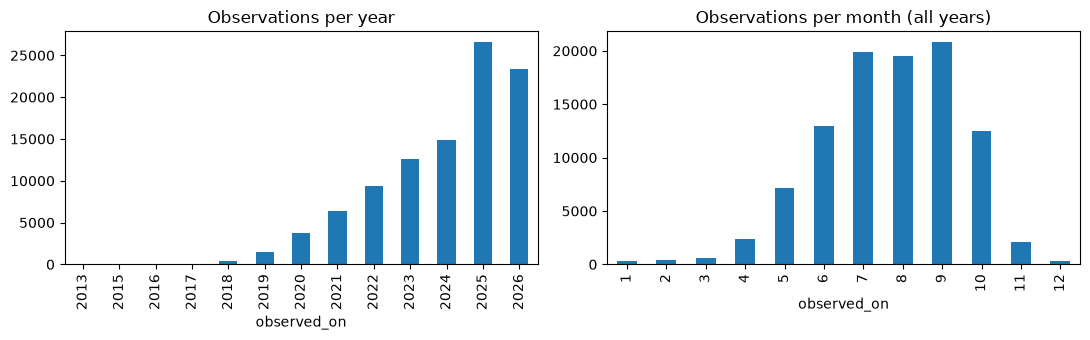

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
obs["observed_on"].dt.year.value_counts().sort_index().plot.bar(ax=ax[0], title="Observations per year")
obs["observed_on"].dt.month.value_counts().sort_index().plot.bar(ax=ax[1], title="Observations per month (all years)")
plt.tight_layout()

Growth over time mixes real spread with growth in iNaturalist use, and the seasonal peak reflects when adults are visible. Both matter for choosing the response variable.

## 2. Assign each sighting to a county

In [7]:
counties = ds.load_counties()
obs = ds.assign_county(obs, counties)
print(f"Sightings outside any county polygon: {obs['fips'].isna().mean():.2%}")
obs["state"].value_counts().head(15)

Sightings outside any county polygon: 0.90%


state
NY    20968
PA    19401
VA    14345
MD    12523
NJ    11287
OH     5592
CT     3156
DC     2695
MA     2482
WV     1428
DE     1146
RI     1136
NC      549
KY      321
MI      305
Name: count, dtype: int64

## 3. County climate (NOAA nClimDiv)

In [8]:
climate = ds.load_climate(start_year=2010)
print(climate.shape)
climate.describe().round(2)

(633828, 7)


,year,month,tavg_f,tmax_f,tmin_f,precip_in
count,633828.0,633828.00,624507.00,624507.00,624507.00,624507.00
mean,2018.0,6.50,55.84,66.97,44.70,3.31
std,4.9,3.45,17.77,18.48,17.29,2.47
min,2010.0,1.00,-7.90,1.40,-17.10,0.00
25%,2014.0,3.75,42.60,53.60,31.80,1.46
50%,2018.0,6.50,57.70,69.80,45.50,2.88
75%,2022.0,9.25,70.60,82.20,59.00,4.61
max,2026.0,12.00,98.10,112.20,85.70,46.04


In [9]:
# Known gaps: future months of the current year, plus a few counties nClimDiv doesn't cover
print("Missing by year:\n", climate[climate["tavg_f"].isna()].groupby("year").size())
no_climate = sorted(set(counties["fips"]) - set(climate["fips"]))
no_climate = counties[counties["fips"].isin(no_climate) & ~counties["state"].isin(["AK", "HI", "PR"])]
print("\nLower-48 counties without climate data:\n", no_climate[["fips", "state", "county"]].to_string(index=False))

Missing by year:
 year
2026    9321
dtype: int64

Lower-48 counties without climate data:
  fips state               county
11001    DC District of Columbia
51678    VA            Lexington


## 4. Preview: county × year

In [10]:
obs["year"] = obs["observed_on"].dt.year

sightings = (obs.dropna(subset=["fips"])
                .groupby(["fips", "year"]).size()
                .rename("slf_sightings").reset_index())

annual = climate.groupby(["fips", "year"]).agg(
    tavg_f=("tavg_f", "mean"),
    coldest_month_tmin_f=("tmin_f", "min"),   # proxy for overwinter egg survival
    precip_in=("precip_in", "sum"),
).reset_index()

preview = annual.merge(sightings, on=["fips", "year"], how="left").fillna({"slf_sightings": 0})
preview = preview.merge(counties[["fips", "state", "county"]], on="fips", how="left")
print(preview.shape)
print(f"County-years with ≥1 sighting: {(preview['slf_sightings'] > 0).mean():.1%}")
preview.sort_values("slf_sightings", ascending=False).head(10)

(52819, 8)
County-years with ≥1 sighting: 3.0%


,fips,year,tavg_f,coldest_month_tmin_f,precip_in,slf_sightings,state,county
47479,51013,2025,57.216667,23.5,36.27,1740.0,VA,Arlington
47853,51059,2025,57.008333,23.2,33.89,1594.0,VA,Fairfax
19939,24031,2025,55.725000,21.8,33.75,1468.0,MD,Montgomery
37600,42003,2023,53.825000,28.5,35.09,1315.0,PA,Allegheny
31021,36061,2023,57.366667,31.3,57.49,1244.0,NY,New York
31020,36061,2022,55.916667,22.6,44.51,1194.0,NY,New York
30545,36005,2023,56.958333,30.7,57.49,1096.0,NY,Bronx
47480,51013,2026,60.488889,22.8,29.90,1078.0,VA,Arlington
30902,36047,2023,57.408333,31.7,57.33,977.0,NY,Kings
30901,36047,2022,56.008333,23.0,42.80,976.0,NY,Kings


Zero sightings ≠ absence: most zeros are counties nobody has looked in yet, or where SLF hasn't arrived. Observer effort still needs to be added before this can be used as a response variable.

## 5. Save processed outputs

In [11]:
ds.PROCESSED.mkdir(parents=True, exist_ok=True)
obs.to_parquet(ds.PROCESSED / "inat_slf_with_county.parquet", index=False)
climate.to_parquet(ds.PROCESSED / "climate_county_month.parquet", index=False)
print(sorted(p.name for p in ds.PROCESSED.glob("*.parquet")))

['climate_county_month.parquet', 'inat_slf_with_county.parquet']


## Data notes
- **nClimDiv sentinels:** the readme says missing temperature is `-99.99`, but the files use `-99.90`. The loader uses a threshold, since cold counties legitimately reach about −17 °F monthly minimum.
- **Connecticut:** nClimDiv uses the old 8 counties, so county boundaries are the 2020 Census file, before CT switched to planning regions.
- **No climate:** Washington DC (11001) and Lexington city, VA (51678). nClimDiv also has an unmatched code `24511` (Maryland), which drops out in joins.
- **Observer-effort bias is visible:** the top county-years are Arlington VA, Fairfax VA, Montgomery MD, Pittsburgh and Manhattan, i.e. where people are, not necessarily where lanternflies are densest.
- **DC:** 2,695 sightings but no nClimDiv climate. Needs a neighbor-county or gridded fill, or exclusion.
- **Location quality:** 5.2% of coordinates are obscured (randomized within ~20 km, so the county may be wrong), and positional accuracy ranges up to thousands of km. Filtering thresholds still need to be chosen.
- **Partial year:** 2026 has climate only through September, so its annual totals aren't comparable to full years.
- **Earliest record is 2013**, before SLF's 2014 first US detection. Probably a date error; check before use.
- **Next:** observer-effort data (all-taxa iNaturalist counts per county-year), host plants (FIA / EDDMapS), and resolving the open decisions.